# 02 - QA/QC and Standardization

**Part A - Foundations - Petrophys Curriculum**

Raw logs are never quite ready for interpretation. Curves carry inconsistent names, mixed
units, physically impossible spikes, and intervals where the borehole itself was too poor
for the tool to read correctly. **Data conditioning** - QA/QC - fixes these before any
physics runs. Garbage in, garbage out is nowhere more true than in petrophysics.

This notebook works through the `petrophys.qaqc` toolkit:

1. **Curve standardization** - map messy mnemonics to standard names, convert units.
2. **Value-range QC** - null out physically impossible values.
3. **Bad-hole / washout detection** - flag intervals where the borehole is unreliable.
4. **Multi-well normalization** - put a curve on a common scale across a field.

## Learning goals

- Standardize mnemonics and units with `CurveStandardizer` / `standardize_curves` and the
  `ALIAS_MAP`.
- Apply value-range QC with `apply_value_range_qc` and read its `value_range_qc_note`.
- Detect washout / bad hole from **caliper (`CALI`)** vs **bit size (`BS`)** with
  `detect_washout` / `WashoutDetection` / `generate_bad_hole_flags`.
- Normalize a curve across wells with `normalize_log`, and understand *why* multi-well
  normalization is needed.
- See **before/after** for each step and be able to justify every QC decision.

## Why this matters

- **Standardization** lets one workflow run over a whole field: if every well calls its
  deep resistivity something different (`RT`, `ILD`, `LLD`, ...), no batch process can find
  it. Mapping them all to `RDEP` fixes that.
- **Value-range QC** removes non-physical readings (a neutron porosity of 3.0, a negative
  gamma ray) that would otherwise poison averages and crossplots.
- **Bad-hole detection** protects density-based answers. Where the hole washes out, the
  density pad loses contact and `RHOB` reads too low - which would fake high porosity. The
  caliper-minus-bit-size, $\mathrm{CALI}-\mathrm{BS}$, is the classic washout indicator.
- **Normalization** removes well-to-well bias (tool calibration, mud, borehole) so that,
  say, a GR cutoff for "clean sand" means the same thing in every well.

### Prerequisites

This notebook assumes **notebooks 00 and 01** - you should be comfortable loading a `Well`,
reading `Curve` statistics, and knowing that Geolink is in metres and Costa in feet.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys version:', petrophys.__version__)

petrophys version: 0.1.0


## 1. Curve standardization

Different vendors and eras name the same measurement differently. *petrophys* ships an
`ALIAS_MAP` (standard mnemonic -> list of known aliases) and a `CurveStandardizer` that uses
it to rename curves and convert units.

Let us take the carbonate well `HW-3`. Its sonic is `DT` and its true resistivity is `RT` -
both non-standard. First, a **dry-run report** shows what *would* change, without touching
the data.

In [2]:
from petrophys.qaqc import CurveStandardizer, standardize_curves, ALIAS_MAP

# A peek at the alias map: many field names all mean "deep resistivity".
print('Aliases that standardize to RDEP:')
print('  ', ALIAS_MAP['RDEP'][:10], '...')

wc = read_las(petrophys.sample('HW-3'))
report = CurveStandardizer().report(wc)

print()
print('HW-3 standardization report')
print('  recognized renames :',
      [(r['original'], r['standard']) for r in report['recognized'] if r['original'] != r['standard']])
print('  unrecognized       :', report['unrecognized'])
print('  unit conversions   :', [(u['curve'], u['from_unit'], '->', u['to_unit'])
                                 for u in report['unit_conversions']])

Aliases that standardize to RDEP:
   ['RT', 'ILD', 'RILD', 'LLD', 'AT60', 'AT90', 'HRLT', 'RESD', 'RD', 'RDEEP'] ...

HW-3 standardization report
  recognized renames : [('DT', 'DTC'), ('RT', 'RDEP')]
  unrecognized       : ['SW_INPUT', 'PERM_CC']
  unit conversions   : [('GR', 'gAPI', '->', 'API')]


The report tells us exactly three things will happen: `DT -> DTC`, `RT -> RDEP`, and the
gamma-ray unit is normalized (`gAPI -> API`). `SW_INPUT` and `PERM_CC` are *unrecognized*
(they are project-specific names), so standardization does not rename them or convert
their units - a safe default. (The value plausibility screen still applies where a range
is configured - `PERM_CC` has one - though no HW-3 values fall outside it.)

Now apply it. `standardize_curves` returns the standardized well (it mutates the well
in place), so we load a fresh copy to keep a clean "before".

In [3]:
before = read_las(petrophys.sample('HW-3'))
after = standardize_curves(read_las(petrophys.sample('HW-3')))

print('curves BEFORE:', before.curves)
print('curves AFTER :', after.curves)
print()
# The DT->DTC rename: same data, standard name.
print('sonic before: DT  present=%s, mean=%.1f %s'
      % (before.has_curve('DT'), before.get('DT').mean(), before.get('DT').unit))
print('sonic after : DTC present=%s, mean=%.1f %s'
      % (after.has_curve('DTC'), after.get('DTC').mean(), after.get('DTC').unit))

curves BEFORE: ['GR', 'RHOB', 'NPHI', 'DT', 'PHIE_CC', 'RT', 'SW_INPUT', 'PERM_CC']
curves AFTER : ['GR', 'RHOB', 'NPHI', 'DTC', 'PHIE_CC', 'RDEP', 'SW_INPUT', 'PERM_CC']

sonic before: DT  present=True, mean=78.4 us/ft
sonic after : DTC present=True, mean=78.4 us/ft


### Unit conversion on a single curve

Standardization also handles units. For finer control you can convert one curve directly
with `convert_curve_units(curve, to_unit)`.

In [4]:
from petrophys.qaqc.standardization import convert_curve_units

gr = read_las(petrophys.sample('HW-3')).get('GR')
gr_api = convert_curve_units(gr, 'API')
print('GR: %s (mean %.2f)  ->  %s (mean %.2f)'
      % (gr.unit, gr.mean(), gr_api.unit, gr_api.mean()))
print('(gAPI and API are the same physical scale, so the numbers are unchanged - only the'
      ' label is standardized.)')

GR: gAPI (mean 12.32)  ->  API (mean 12.32)
(gAPI and API are the same physical scale, so the numbers are unchanged - only the label is standardized.)


## 2. Value-range QC

`apply_value_range_qc(well)` walks each curve, looks up its configured plausible range in
`VALUE_RANGE_RULES`, and either **nulls** (sets to NaN) or **clips** out-of-range values. It
returns a per-curve report; `value_range_qc_note` renders that report as a readable sentence.

We use the Geolink well `30_6-5` because its raw curves contain real out-of-range values
(a handful of negative GR samples, out-of-bounds NPHI, and huge resistivity spikes).

In [5]:
from petrophys.qaqc import apply_value_range_qc, value_range_qc_note

w = read_las(petrophys.sample('30_6-5'))

# capture BEFORE stats for the affected curves
before_stats = {c: (w.get(c).min(), w.get(c).max()) for c in ['GR', 'NPHI', 'RDEP']}

report = apply_value_range_qc(w)   # mutates w: out-of-range -> NaN / clipped
changed = [r for r in report if r.get('changed')]

print('Curves changed by value-range QC:')
for r in changed:
    print('  %-6s %d values fixed (below=%d, above=%d) - action=%s [range %.3g..%.3g]'
          % (r['curve'], r['changed'], r['below'], r['above'], r['action'], r['low'], r['high']))

Curves changed by value-range QC:
  NPHI   299 values fixed (below=0, above=299) - action=nan [range -0.15..0.6]
  PEF    35 values fixed (below=0, above=35) - action=nan [range 0..15]
  GR     3 values fixed (below=3, above=0) - action=nan [range 0..400]
  RDEP   9 values fixed (below=0, above=9) - action=nan [range 0.01..2e+03]


In [6]:
# Before/after min-max for the affected curves.
rows = []
for c in ['GR', 'NPHI', 'RDEP']:
    lo0, hi0 = before_stats[c]
    cc = w.get(c)
    rows.append({'curve': c,
                 'min_before': round(lo0, 3), 'max_before': round(hi0, 3),
                 'min_after': round(cc.min(), 3), 'max_after': round(cc.max(), 3)})
print(pd.DataFrame(rows).to_string(index=False))
print()
print('Human-readable note:')
print(value_range_qc_note(report))

curve  min_before  max_before  min_after  max_after
   GR     -12.593     238.000      5.445    238.000
 NPHI       0.001       0.680      0.001      0.600
 RDEP       0.409    2000.016      0.409   1999.998

Human-readable note:
VALUE RANGE QC: finite values outside configured ranges were set to NaN; SW/SWA and SXO/SWXO/SWXOA were clipped to 0-1. Changed: NPHI set NaN=299 (<-0.15:0, >0.6:299); PEF set NaN=35 (<0.0:0, >15.0:35); GR set NaN=3 (<0.0:3, >400.0:0); RDEP set NaN=9 (<0.01:0, >2000.0:9).


**Reading the result:** the negative gamma-ray samples (physically impossible - GR cannot
be below 0) were nulled, and out-of-bounds neutron porosity was removed. The RDEP values
above 2000 ohm.m are a different case: that bound is a configured plausibility/tool screen,
not a law of physics - tight, resistive rock can legitimately read higher (sister well
`16_7-1` does) - so it is a reviewable screening choice, not a hard physical edit. That mix
is exactly why value-range QC uses a *curve-specific* rule table rather than a blanket
filter: some rules encode physics, others encode plausibility.

## 3. Bad-hole / washout detection

When the borehole caves or washes out, pad-contact tools (especially density) read
unreliably. The primary indicator is the caliper exceeding the bit that drilled the hole:

$$\text{washout where } \quad (\mathrm{CALI} - \mathrm{BS}) > \text{threshold} \quad (\text{default } 1.5\ \text{in})$$

An independent check is the density correction $|\mathrm{DRHO}|$ exceeding a threshold. The
combined **bad-hole flag** is the union of the washout and large-hole flags; the
low-density and PEF-exclusion screens are computed separately and reported
alongside it for QC reference.

`30_6-5` carries both **`CALI`** (caliper) and **`BS`** (bit size), so it is the right well
for this demo.

In [7]:
from petrophys.qaqc import detect_washout, WashoutDetection, generate_bad_hole_flags

w = read_las(petrophys.sample('30_6-5'))
cali, bs = w.get('CALI'), w.get('BS')
print('CALI (in): min %.1f  median %.1f  max %.1f' % (cali.min(), cali.median(), cali.max()))
print('BS   (in): min %.1f  median %.1f  max %.1f' % (bs.min(), bs.median(), bs.max()))
print()

result = detect_washout(w)   # auto-uses the BS curve when no header bit size is set
s = result.statistics
print('Detection summary (%% of the logged interval):')
print('  washout      : %5.1f %%  (%.1f m)' % (s['washout_percent'], s['washout_thickness']))
print('  large hole   : %5.1f %%' % s['large_hole_percent'])
print('  low density  : %5.1f %%' % s['low_density_percent'])
print('  bad hole (all): %5.1f %%  (%.1f m)' % (s['bad_hole_percent'], s['bad_hole_thickness']))
print()
print('Number of distinct washout intervals:', len(result.washout_intervals))
print('First few (top, bottom) in m:', [(round(a,1), round(b,1)) for a, b in result.washout_intervals[:3]])

CALI (in): min 8.2  median 14.4  max 24.1
BS   (in): min 8.5  median 12.2  max 36.0

Detection summary (%% of the logged interval):
  washout      :  35.4 %  (1194.6 m)
  large hole   :  23.0 %
  low density  :  49.8 %
  bad hole (all):  57.0 %  (1924.3 m)

Number of distinct washout intervals: 736
First few (top, bottom) in m: [(901.3, 949.6), (955.1, 955.5), (955.8, 960.9)]


### Visualizing the washout

Bad hole is labeled the way every petrophys interpretation plot labels it: the log
viewer shades the affected depths in pink across the tracks and adds a **BADHOLE**
entry to the legend. The triple combo is enough to tell the story: the GR / CALI
track carries CALI against the dashed BS (the cause), and the NEUTRON / DENSITY / SONIC
track carries RHOB and DRHO (the tools you stop trusting). We window in on a heavily
washed-out section, around the bit change at ~1815 m and the enlarged hole below it; the
full-well extent (57% flagged) is in the detection summary above.

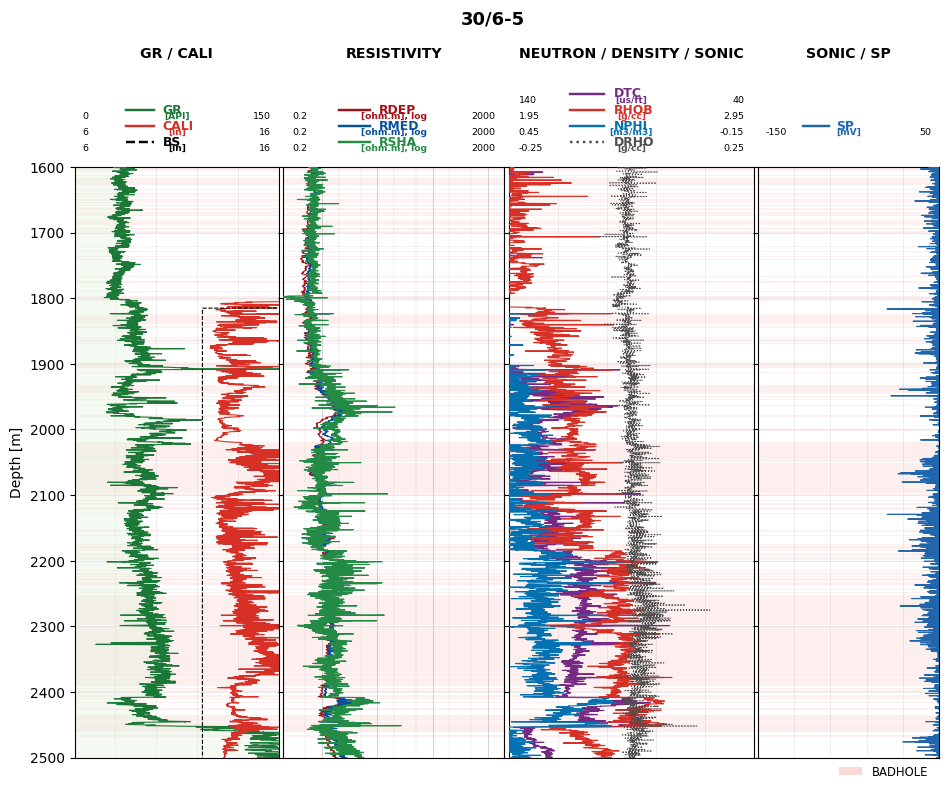

In [8]:
# Attach the indicator flags, then display bad hole the way the library labels
# it: the viewer shades flagged depths pink on every track (BADHOLE legend).
from petrophys.visualization import create_log_viewer

flags = generate_bad_hole_flags(w)
for key, name, desc in [
    ('washout',       'WASHOUT_FLAG',     'CALI - BS > 1.5 in or |DRHO| > 0.15 g/cc'),
    ('large_hole',    'LARGE_HOLE_FLAG',  'BS > 17.5 in'),
    ('low_density',   'LOW_DENSITY_FLAG', 'RHOB < 2.1 g/cc screen'),
    ('pef_exclusion', 'PEF_EXCL_FLAG',    'PEF outside 0.5-7 b/e'),
    ('bad_hole',      'BAD_HOLE_FLAG',    'washout OR large hole'),
]:
    w.add_curve(name, flags[key].astype(float), unit='', description=desc)

viewer = create_log_viewer(w, template_defaults='triple_combo',
                           depth_range=(1600, 2500), figsize=(9, 8))

### Attaching flags to the well

For downstream use you usually want the flags *as curves* on the well. `WashoutDetection`
can add them for you, so later steps can mask bad intervals out.

In [9]:
w_flagged = read_las(petrophys.sample('30_6-5'))
WashoutDetection().add_flags_to_well(w_flagged)

print('Flag curves added:',
      [c for c in w_flagged.curves if 'FLAG' in c])
wf = w_flagged.get('BAD_HOLE_FLAG')
print('BAD_HOLE_FLAG: %d of %d samples flagged (%.1f%%)'
      % (int(np.nansum(wf.data)), w_flagged.n_samples,
         100 * np.nansum(wf.data) / w_flagged.n_samples))

Flag curves added: ['WASHOUT_FLAG', 'BAD_HOLE_FLAG', 'PEF_EXCL_FLAG']
BAD_HOLE_FLAG: 12631 of 22176 samples flagged (57.0%)


## 4. Multi-well normalization

Even after standardization, a curve's *values* can be biased well-to-well - different tool
calibration, mud, or borehole conditions shift the readings. Before comparing wells (or
applying a single cutoff across a field), we **normalize** to a common scale.

`normalize_log` applies a linear rescale using low/high anchor points (typically robust
percentiles like p5/p95 so outliers do not distort the fit):

$$\text{norm} = \text{min} + (\text{max}-\text{min})\,\frac{\text{log}-\text{low}}{\text{high}-\text{low}}$$

We use several **Costa** wells. First, look at how their raw GR distributions differ.

In [10]:
from petrophys.qaqc import normalize_log

costa_names = ['HW-3', 'HW-4', 'HW-5', 'HW-6', 'HW-7']
costa = {n: read_las(petrophys.sample(n)) for n in costa_names}

print('Raw GR per Costa well (before normalization):')
rows = []
for n, ww in costa.items():
    g = ww.get('GR')
    rows.append({'well': n, 'p5': round(g.percentile(5), 1),
                 'median': round(g.median(), 1), 'p95': round(g.percentile(95), 1)})
print(pd.DataFrame(rows).to_string(index=False))

Raw GR per Costa well (before normalization):


well   p5  median  p95
HW-3  8.8    10.8 20.5
HW-4 10.0    12.0 33.0
HW-5 13.6    16.6 42.9
HW-6  7.6     9.9 28.0
HW-7  7.0     9.6 33.0


The p5/p95 anchors drift from well to well (HW-3 tops out near 20, HW-5 near 43). If we
applied a single GR cutoff to pick clean carbonate, it would mean different things in
different wells. Normalizing each well's GR onto a **common 0-100 scale** - mapping each
well's own p5 to 0 and p95 to 100 - removes that bias.

In [11]:
# Normalize each well's GR: its own p5 -> 0, p95 -> 100 on a common scale.
norm_gr = {}
for n, ww in costa.items():
    g = ww.get('GR')
    norm_gr[n] = normalize_log(g.data, log_min=0.0, log_max=100.0,
                               log_low=g.percentile(5), log_high=g.percentile(95))

print('After normalization (all wells now share the same anchors):')
rows = []
for n in costa_names:
    arr = norm_gr[n]
    rows.append({'well': n,
                 'p5': round(float(np.nanpercentile(arr, 5)), 1),
                 'median': round(float(np.nanmedian(arr)), 1),
                 'p95': round(float(np.nanpercentile(arr, 95)), 1)})
print(pd.DataFrame(rows).to_string(index=False))

After normalization (all wells now share the same anchors):
well   p5  median   p95
HW-3  0.0    17.0 100.0
HW-4  0.0     8.7 100.0
HW-5 -0.0    10.3 100.0
HW-6 -0.0    11.0 100.0
HW-7  0.0    10.0 100.0


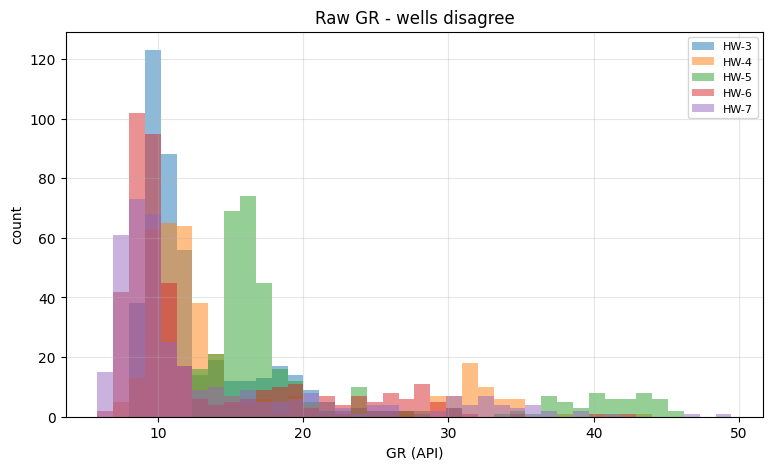

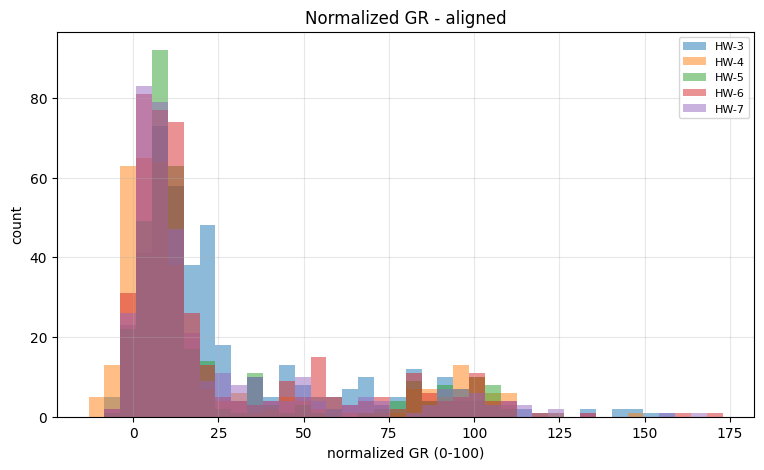

In [12]:
# Before/after distribution comparison via the library histogram plotter.
from petrophys.visualization import create_histogram_comparison

raw = {n: ww.get('GR').data for n, ww in costa.items()}
norm = {n: norm_gr[n] for n in costa_names}

create_histogram_comparison(raw, bins=40, xlabel='GR (API)',
                            title='Raw GR - wells disagree')
plt.show()

create_histogram_comparison(norm, bins=40, xlabel='normalized GR (0-100)',
                            title='Normalized GR - aligned')
plt.show()

The second (normalized) histogram shows the distributions brought into register: a normalized GR of, say,
20 now marks the same relative "cleanness" in every well, so a field-wide cutoff behaves
consistently. (Choosing p5/p95 as anchors assumes each well truly samples both clean and
shaly rock - always sanity-check that assumption before normalizing.)

## Pitfalls and parameter choices

- **Standardize first, everything else second.** Bad-hole, value-range, and normalization
  all look curves up by name; if names are inconsistent they silently miss curves.
- **`standardize_curves` mutates the well.** Load a fresh copy if you need an untouched
  "before" for comparison.
- **Bad-hole needs a bit-size source.** With no header bit size, detection falls back to the
  `BS` curve; with neither, the `CALI-BS` test cannot fire (only `|DRHO|` remains). Costa
  wells have no caliper, which is why we demoed washout on Geolink.
- **Value-range QC is curve-specific.** It uses a physical rule per mnemonic, so a
  standardized name is what unlocks the right rule.
- **Normalization anchors are assumptions.** p5/p95 are robust, but if a well never
  penetrates clean rock, forcing its p5 to 0 will over-clean it. Pick anchors that reflect a
  shared geological reference where possible.

## Recap

- **Standardization** (`CurveStandardizer` / `standardize_curves`, `ALIAS_MAP`) maps
  aliases like `DT`/`RT` to standard `DTC`/`RDEP` and normalizes units - do it first.
- **Value-range QC** (`apply_value_range_qc`, `value_range_qc_note`) nulls or clips
  physically impossible or implausible readings using a per-curve rule table (some
  bounds are physics, others - like RDEP > 2000 ohm.m - are plausibility screens).
- **Bad-hole detection** (`detect_washout` / `WashoutDetection` / `generate_bad_hole_flags`)
  flags unreliable intervals from `CALI-BS` (and `DRHO`), and can attach the flags as curves.
- **Normalization** (`normalize_log`) rescales a curve to a common range across wells so
  field-wide cutoffs are meaningful.
- Always inspect **before/after** and be able to justify each edit physically.

## Try it yourself

> **Exercise 1.** Run `CurveStandardizer().report(...)` on a Geolink well (e.g. `15_9-14`).
> Which curves are recognized, and are any unit conversions proposed?
>
> **Exercise 2.** Re-run `detect_washout` on `30_6-5` with a stricter caliper threshold
> (`detect_washout(w, cali_threshold=0.75)`). Does the flagged bad-hole percentage go up or
> down, and why?
>
> **Exercise 3.** Normalize `RHOB` (instead of GR) across the five Costa wells using p5/p95
> anchors and overlay the before/after histograms. Does density need normalization as much
> as gamma ray does?

## What's next

That completes the data-conditioning trio (00-02), but **Part A - Foundations** keeps
going: notebooks 03 through 09 build the core interpretation science on this clean
foundation - clay/shale volume from the gamma ray (**`03_clay_volume.ipynb`** is next),
then porosity, lithology and mineral solving, formation water, water saturation,
permeability, and reservoir quality / net pay. **Part B** (notebooks 10-18) is the
advanced track: the dynamic workflow, formation analysis, core and digital core, ML
imputation, NMR, capillary pressure, borehole images, the visualization masterclass,
and the multiwell field study. Everything downstream consumes exactly the conditioned
`Well` you have learned to produce here.